In [2]:
import os 
from dotenv import load_dotenv
from langchain_groq import ChatGroq
from langchain.chat_models import init_chat_model
load_dotenv()

True

In [3]:

farm_data = {
    # Farm Information
    "farmName": "Demo Farm",
    "location": "Damanhur, Beheira, Egypt",
    "latitude": 31.04,
    "longitude": 30.47,
    "cultivatedArea": 5.0,
    "areaUnit": "Acres",

    # Soil Information
    "soilType": "Sandy loam",
    "soilPH": 7.5,
    "soilSalinityEC": 1.2,       # dS/m
    "soilOrganicMatter": 1.8,    # %

    # Crop Information
    "currentCrop": "Maize",
    "previousWinterCrop": "Wheat",
    "cropHistory": [
        {"crop": "Wheat", "season": "Winter", "year": 2024},
        {"crop": "Maize", "season": "Summer", "year": 2024},
        {"crop": "Wheat", "season": "Winter", "year": 2025},
        {"crop": "Maize", "season": "Summer", "year": 2025}
    ],
    "plantingDate": "2026-05-01",
    "expectedHarvestDate": "2026-09-15",

    # Irrigation Information
    "waterSource": "Nile irrigation canal",
    "irrigationMethod": "Surface irrigation",
    "irrigationFrequency": "Every 10 days",
    "availableWaterAmount": 3000,  # m3 per acre per season

    # Farmer Goal
    "farmerGoal": [
        "Improve soil health",
        "Maintain crop productivity",
        "Reduce water consumption"
    ],
    "goalPriority": [
        "Improve soil health",
        "Maintain crop productivity",
        "Reduce water consumption"
    ]
}


In [21]:
import requests
import pandas as pd
import json

NASA_POWER_URL = (
    "https://power.larc.nasa.gov/api/temporal/daily/point"
)
def get_nasa_data(latitude, longitude, start_date, end_date):

    params = {
        "parameters": (
            "T2M,T2M_MAX,T2M_MIN,"
            "PRECTOTCORR,ALLSKY_SFC_SW_DWN"
        ),
        "community": "AG",
        "longitude": longitude,
        "latitude": latitude,
        "start": start_date,
        "end": end_date,
        "format": "JSON",
        "time-standard": "UTC"
    }

    response = requests.get(
        NASA_POWER_URL,
        params=params,
        timeout=60
    )

    response.raise_for_status()

    result = response.json()

    parameter_data = result["properties"]["parameter"]

    df = pd.DataFrame(parameter_data)

    # Convert date index into a normal column
    df.index = pd.to_datetime(
        df.index,
        format="%Y%m%d"
    )

    df.index.name = "date"

    df = df.reset_index()

    # Replace missing values
    df = df.replace(-999, float("nan"))

    return df




In [22]:
latitude = farm_data["latitude"]
longitude = farm_data["longitude"]

df = get_nasa_data(
    latitude=latitude,
    longitude=longitude,
    start_date="20261101",
    end_date="20261114"
)

display(df.head())

,date,T2M,T2M_MAX,T2M_MIN,PRECTOTCORR,ALLSKY_SFC_SW_DWN
0,2026-11-01,23.59,31.01,17.07,0.00,NaN
1,2026-11-02,24.86,34.31,17.79,0.00,NaN
2,2026-11-03,24.24,32.02,19.08,0.02,NaN
3,2026-11-04,23.99,32.57,17.42,0.00,NaN
4,2026-11-05,22.45,28.35,18.66,0.40,NaN


In [5]:
def safe_round(value, digits=2):

    if pd.isna(value):
        return None

    return round(float(value), digits)



In [6]:
def analyze_environment(df):

    df = df.copy()
    df["date"] = pd.to_datetime(df["date"])
    df["month"] = df["date"].dt.month

    monthly_temperature = (
        df.groupby("month")["T2M"]
        .mean()
        .reindex(range(1, 13))
    )

    monthly_precipitation = (
        df.groupby("month")["PRECTOTCORR"]
        .sum(min_count=1)
        .reindex(range(1, 13))
    )

    environment_data = {
        "temperature": safe_round(df["T2M"].mean()),

        "precipitation": safe_round(
            df["PRECTOTCORR"].sum(min_count=1)
        ),

        "soilMoisture": None,
        "landSurfaceTemperature": None,
        "vegetationIndex": None,
        "solarRadiation": None,
        "growingSeasonDays": None,

        "monthlyMeanTemperatureC": [
            safe_round(v) for v in monthly_temperature
        ],

        "monthlyPrecipitationMm": [
            safe_round(v) for v in monthly_precipitation
        ]
    }

    return {
        "location": farm_data["location"],

        "period": {
            "start": str(df["date"].min().date()),
            "end": str(df["date"].max().date())
        },

        "averageTemperatureC": safe_round(
            df["T2M"].mean()
        ),

        "maximumDailyTemperatureC": safe_round(
            df["T2M_MAX"].max()
        ),

        "minimumDailyTemperatureC": safe_round(
            df["T2M_MIN"].min()
        ),

        "totalPrecipitationMm": safe_round(
            df["PRECTOTCORR"].sum(min_count=1)
        ),

        "environmentData": environment_data,

        "dataSource": "NASA POWER"
    }

In [23]:
environment_summary = analyze_environment(df)

print(
    json.dumps(
        environment_summary,
        indent=4,
        ensure_ascii=False
    )
)

{
    "location": "Damanhur, Beheira, Egypt",
    "period": {
        "start": "2026-11-01",
        "end": "2026-11-14"
    },
    "averageTemperatureC": 21.65,
    "maximumDailyTemperatureC": 34.31,
    "minimumDailyTemperatureC": 13.74,
    "totalPrecipitationMm": 2.8,
    "environmentData": {
        "temperature": 21.65,
        "precipitation": 2.8,
        "soilMoisture": null,
        "landSurfaceTemperature": null,
        "vegetationIndex": null,
        "solarRadiation": null,
        "growingSeasonDays": null,
        "monthlyMeanTemperatureC": [
            null,
            null,
            null,
            null,
            null,
            null,
            null,
            null,
            null,
            null,
            21.65,
            null
        ],
        "monthlyPrecipitationMm": [
            null,
            null,
            null,
            null,
            null,
            null,
            null,
            null,
            null,
          

In [24]:
from langchain_core.tools import tool
from langchain_tavily import TavilySearch



def get_farm_environment() -> str:
    """
    Retrieve NASA POWER climate data for the demo farm.
    Analyze average temperature, maximum and minimum temperature,
    precipitation, and monthly climate summaries.
    """

    global latest_environment

    df = get_nasa_data(
        latitude=farm_data["latitude"],
        longitude=farm_data["longitude"],
        start_date="20250101",
        end_date="20251231"
    )

    latest_environment = analyze_environment(
        df
        
    )

    return json.dumps(
        latest_environment,
        ensure_ascii=False
    )


# Tavily Search Tool
from langchain_tavily import TavilySearch

tavily_search = TavilySearch(
    max_results=5,
    search_depth="basic"
)


# All available tools
tools = [
    get_farm_environment,
    tavily_search
]

In [ ]:
# system_prompt = """
# You are Field Shift, an agricultural decision-support AI agent.

# ## Objective
# Generate exactly 3 distinct crop rotation strategies tailored to the farmer's profile, NASA environmental data, and reliable agricultural research.

# ## Workflow
# 1. Analyze the farm profile and crop history.
# 2. Use NASA tools to retrieve and analyze environmental data for the farm location.
# 3. Use TavilySearch to find reliable agricultural research on crop requirements, seasonal suitability, water needs, and crop rotation practices.
# 4. Generate 3 distinct strategies: the current rotation as a baseline (if available) and two evidence-based alternatives.
# 5. Evaluate and compare strategies based on climate, soil, water availability, crop history, and farmer goals.

# ## Rules
# - Generate crop sequences dynamically; never use hardcoded recommendations.
# - Prefer NASA, FAO, Egyptian agricultural research institutions, universities, and peer-reviewed scientific papers.
# - Support every important agricultural claim with retrieved evidence.
# - Include the actual source title, organization, publication year (if available), and direct URL.
# - Never invent data, research, citations, or crop requirements.
# - Distinguish NASA observations, published research, and AI interpretations.
# - Identify missing information and explain its impact.
# - Never claim a strategy is optimal without sufficient evidence.
# - If evidence is insufficient, lower confidence and clearly state the limitations.

# ## Output
# Return valid JSON only:

# {
#   "strategies": [
#     {
#       "strategy_id": "strategy_1",
#       "name": "Strategy name",
#       "crop_sequence": ["Winter crop", "Summer crop"],
#       "rationale": ["Evidence-based reasons"],
#       "potential_benefits": ["Potential benefits"],
#       "risks": ["Potential risks"],
#       "environmental_analysis": ["NASA findings with values and units"],
#       "evidence_sources": [
#         {
#           "title": "Source title",
#           "organization": "Publisher or institution",
#           "year": null,
#           "url": "Direct source URL",
#           "supports": "Claim supported by this source"
#         }
#       ],
#       "missing_information": ["Unavailable data"],
#       "confidence_level": "Low | Medium | High"
#     }
#   ],
#   "overall_comparison": "Compare the three strategies and their trade-offs.",
#   "recommended_strategy": "Strategy ID or null",
#   "recommendation_reason": "Evidence-based explanation"
# }

# Return exactly 3 strategies. Return only valid JSON.
# """

In [9]:
from typing import TypedDict


class FarmState(TypedDict):
    farm_profile: dict

    nasa_data: dict
    environment_analysis: dict

    research_results: list

    strategies: list
    comparison: dict
    recommendation: dict

In [10]:
def analyze_nasa_node(state: FarmState):

    farm = state["farm_profile"]

    # Get NASA POWER data
    df = get_nasa_data(
        latitude=farm["latitude"],
        longitude=farm["longitude"],
        start_date="20250101",
        end_date="20251231"
    )

    # Analyze climate data
    environment_summary = analyze_environment(df)

    return {
        "nasa_data": {
            "source": "NASA POWER",
            "period": "2025-01-01 to 2025-12-31",
            "parameters": [
                "T2M",
                "T2M_MAX",
                "T2M_MIN",
                "PRECTOTCORR"
            ]
        },
        "environment_analysis": environment_summary
    }

In [11]:
llm = ChatGroq(
    model="openai/gpt-oss-20b",
    temperature=0
)

In [12]:
from langchain.agents import create_agent
from langgraph.checkpoint.memory import InMemorySaver


memory = InMemorySaver()


agent = create_agent(
    model=llm,

    tools=tools,

    # system_prompt=system_prompt,

    checkpointer=memory
)

In [13]:

import json


def generate_strategies_node(state: FarmState):

    # 1. Keep only the necessary farm information
    farm = state["farm_profile"]

    farm_context = {
        key: farm.get(key)
        for key in [
            "location",
            "latitude",
            "longitude",
            "soilType",
            "currentCrop",
            "previousWinterCrop",
            "cropHistory",
            "waterSource",
            "irrigationMethod",
            "farmerGoal"
        ]
        if farm.get(key) is not None
    }

    # 2. Extract the research summary and source links
    research_context = []
    for item in state.get("research_results", []):

        research_context.append({
            "summary": item.get("research_summary", "")[:2500],
            "sources": [
                {
                    "title": source.get("title"),
                    "url": source.get("url")
                }
                for source in item.get("retrieved_sources", [])
                if source.get("url")
            ][:5]
        })

    # 3. Prepare a short prompt
    prompt = f"""
You are an agricultural decision-support assistant.

Generate exactly 3 different crop rotation strategies.

Farm profile:
{json.dumps(farm_context, ensure_ascii=False)}

NASA environmental analysis:
{json.dumps(state["environment_analysis"], ensure_ascii=False)}

Agricultural research:
{json.dumps(research_context, ensure_ascii=False)}

Requirements:
1. Each strategy must contain a crop sequence.
2. Explain its main benefit in ONE short sentence.
3. Include a real source title and URL from the research.
4. Do not invent crops, findings, or sources.
5. Use NASA data to consider the farm's climate conditions.
6. Do not assume missing information.
7. If evidence is insufficient, clearly mention it.

Return ONLY valid JSON with exactly this structure:

{{
    "strategies": [
        {{
            "name": "Strategy name",
            "crop_sequence": ["Crop 1", "Crop 2" ,"Crop 3"],
            "benefit": "One short sentence.",
            "source": {{
                "title": "Source title",
                "url": "Source URL"
            }}
        }}
    ]
}}
"""

    # 4. Generate strategies
    response = llm.invoke(prompt, max_tokens=1200)

    # 5. Parse the JSON response
    content = response.content.strip()

    if content.startswith("```"):
        content = content.split("\n", 1)[1].rsplit("```", 1)[0]

    try:
        result = json.loads(content)

    except json.JSONDecodeError as e:
        print("Invalid JSON returned by the model:")
        print(content)
        raise ValueError(
            f"Could not parse strategies JSON: {e}"
        ) from e

    # 6. Basic output validation
    strategies = result.get("strategies", [])

    if len(strategies) != 3:
        raise ValueError(
            f"Expected exactly 3 strategies, got {len(strategies)}"
        )

    return {
        "strategies": strategies
    }


In [17]:

# def build_research_query(farm: dict) -> str:

#     farm_context = f"""
#     Farm location: {farm.get("location", "Not provided")}
#     Soil type: {farm.get("soilType", "Not provided")}
#     Current crop: {farm.get("currentCrop", "Not provided")}
#     Previous winter crop: {farm.get("previousWinterCrop", "Not provided")}
#     Crop history: {farm.get("cropHistory", "Not provided")}
#     Water source: {farm.get("waterSource", "Not provided")}
#     Irrigation method: {farm.get("irrigationMethod", "Not provided")}
#     Farmer goals: {farm.get("farmerGoal", "Not provided")}
#     """

#     return f"""
#     Find reliable agricultural research relevant to this farm:

#     {farm_context}

#     Research objectives:

#     1. Identify possible crop rotation options suitable
#        for the farm's geographical location and climate.

#     2. Identify crops that can be grown in the appropriate
#        agricultural seasons.

#     3. Investigate the effects of previous crops on the
#        current crop.

#     4. Find crop water requirements and irrigation needs.

#     5. Investigate effects of crop rotation on soil fertility
#        and soil health.

#     6. Identify risks and limitations of each potential option.

#     Search for evidence relevant to the supplied farm profile.
#     Do not assume a particular crop or country.

#     Prioritize official agricultural institutions,
#     universities, FAO publications, and peer-reviewed studies.

#     Return source titles, publishers, publication years,
#     direct URLs, and relevant findings.
#     """



import json


def build_research_queries(farm: dict, climate: dict) -> list[str]:

    history = farm.get("cropHistory", [])

    if isinstance(history, list):
        previous_crops = [
            item.get("crop") if isinstance(item, dict) else item
            for item in history
        ]
    else:
        previous_crops = [history]

    previous_crops = [
        crop for crop in previous_crops if crop
    ]

    soil_info = {
        key: value
        for key, value in farm.items()
        if key.lower().startswith("soil")
        and value is not None
    }

    goals = farm.get("farmerGoal", [])
    if isinstance(goals, str):
        goals = [goals]

    farm_context = f"""
    Location: {farm.get("location")}
    Soil: {farm.get("soilType")}
    Soil measurements: {json.dumps(soil_info)}
    Current crop: {farm.get("currentCrop")}
    Crop history: {previous_crops}
    Farmer goals: {goals}
    Water source: {farm.get("waterSource")}
    """

    # Pass only relevant climate indicators
    climate_context = json.dumps(
        climate,
        ensure_ascii=False,
        default=str
    )[:1200]

    return [

        f"""
        Find peer-reviewed studies and agricultural research
        about crop rotation systems suitable for this location:

        {farm_context}

        Climate observations:
        {climate_context}

        Identify alternative crop sequences for the actual
        agricultural seasons in this region.

        Prioritize studies from the same country or nearby
        agro-climatic regions.

        Return crop sequences, planting seasons, soil conditions,
        study location, publication year and source URL.
        """,

        f"""
        Find quantitative studies comparing water requirements
        of different crop rotations under similar climate and soil
        conditions.

        Farm context:
        {farm_context}

        Climate:
        {climate_context}

        Look for:
        - Water requirement per crop and per rotation.
        - Seasonal irrigation requirement.
        - Crop evapotranspiration (ETc).
        - Water productivity.
        - Direct comparisons with a baseline rotation.

        Report numerical values with units, study location,
        baseline and methodology.

        Do not interpret water productivity as water saving.
        """,

        f"""
        Find experimental and long-term studies about the effects
        of alternative crop rotations on soil properties.

        Farm context:
        {farm_context}

        Focus on measured changes in:
        - Soil organic carbon and organic matter.
        - Soil nitrogen and nutrient availability.
        - Soil salinity and electrical conductivity.
        - Soil structure and water retention.

        Prioritize studies with similar soil properties.
        Report the crop sequence, soil type, study duration,
        measured change, units and source URL.
        """,

        f"""
        Find research about climate change impacts on crop
        suitability and crop rotation decisions in:

        Location: {farm.get("location")}

        Observed NASA climate indicators:
        {climate_context}

        Investigate:
        - Temperature and rainfall impacts on crop growth.
        - Changing growing seasons.
        - Heat and drought stress.
        - Climate-adaptive alternative crop sequences.

        Prioritize local agricultural research institutions,
        universities, FAO and peer-reviewed scientific papers.

        Return evidence, not general recommendations.
        """
    ]


def research_node(state: FarmState):

  

    farm = state["farm_profile"]

    query = build_research_queries(farm)

    search_response = tavily_search.invoke({
        "query": query
    })

    results = search_response.get("results", [])[:5]

    compact_results = [
        {
            "title": item.get("title"),
            "url": item.get("url"),
            "content": item.get("content", "")[:1200]
        }
        for item in results
    ]

    prompt = f"""
    You are an agricultural research analyst.

    Farm profile:
    {json.dumps(farm, ensure_ascii=False)}

    Retrieved research:
    {json.dumps(compact_results, ensure_ascii=False)}

    Analyze the retrieved evidence.

    Extract:
    1. Relevant agricultural findings.
    2. Potential crop rotation options supported by evidence.
    3. Claims supported by each source.
    4. Source limitations.
    5. Missing information.

    Do not invent crops, findings, or citations.
    Do not assume that a crop is suitable without evidence.
    Keep original source URLs.

    Respond in Arabic.
    """

    response = llm.invoke(prompt)

    return {
        "research_results": [
            {
                "retrieved_sources": compact_results,
                "research_summary": response.content
            }
        ]
    }



In [18]:

def retrieve_agricultural_research(
    farm: dict,
    climate_analysis: dict,
    tavily_search
) -> list[dict]:

    queries = build_research_queries(
        farm,
        climate_analysis
    )

    retrieved_sources = []
    seen_urls = set()

    for query in queries:

        response = tavily_search.invoke({
            "query": query
        })

        # Handle the common Tavily response structure
        if isinstance(response, dict):
            results = response.get("results", [])
        else:
            print("Unexpected Tavily response:", type(response))
            continue

        for item in results:

            url = item.get("url")

            if not url or url in seen_urls:
                continue

            seen_urls.add(url)

            retrieved_sources.append({
                "title": item.get("title", ""),
                "url": url,
                "content": item.get("content", "")[:1000],
                "query_context": query[:200]
            })

    return retrieved_sources


In [25]:

research_sources = retrieve_agricultural_research(
    farm=farm_data,
    climate_analysis=environment_summary,
    tavily_search=tavily_search
)

print("Number of sources:", len(research_sources))

for source in research_sources:
    print("\nTitle:", source["title"])
    print("URL:", source["url"])
    print("Evidence:", source["content"][:300])


Number of sources: 19

Title: Utilizing Different Crop Rotation Systems for Agricultural and Environmental Sustainability: A Review
URL: https://www.mdpi.com/2073-4395/15/8/1966
Evidence: rotation and its contribution to promoting sustainable farming practices, such as legume integration and cover cropping. It is based on a thematic literature review of peer-reviewed studies published between 1984 and 2025. We found that crop rotation can significantly improve soil structure and orga

Title: Crop Rotation Practices and Their Impact on Soil Fertility
URL: https://www.agroresearchjournal.com/uploads/archives/20250611164406_8.pdf
Evidence: overall soil biological activity by 35-40%. The study compares traditional monocropping systems with various rotation patterns including legume-cereal rotations, cover crop integration, and multi-species rotations. Findings indicate that diversified rotation systems not only restore soil fertility b

Title: Crop Rotation: Benefits Of Using And Applicati

In [16]:
def validate_node(state: FarmState):

    strategies = state["strategies"]

    errors = []

    if len(strategies) != 3:
        errors.append("Expected exactly 3 strategies.")

    for strategy in strategies:

        required_fields = [
            "strategy_id",
            "name",
            "crop_sequence",
            "rationale",
            "risks",
            "evidence_sources",
            "missing_information",
            "confidence_level"
        ]

        for field in required_fields:
            if field not in strategy:
                errors.append(
                    f"{strategy.get('strategy_id', 'Unknown')}: "
                    f"Missing field {field}"
                )

    if errors:
        raise ValueError("\n".join(errors))

    return {}

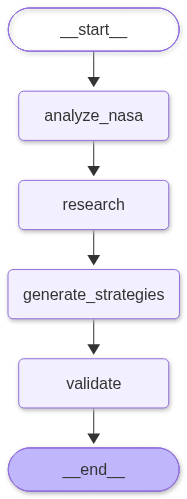

In [ ]:
from langgraph.graph import StateGraph, START, END


graph_builder = StateGraph(FarmState)

# Add nodes
graph_builder.add_node(
    "analyze_nasa",
    analyze_nasa_node
)

graph_builder.add_node(
    "research",
    research_node
)

graph_builder.add_node(
    "generate_strategies",
    generate_strategies_node
)

graph_builder.add_node(
    "validate",
    validate_node
)

# Define execution order
graph_builder.add_edge(START, "analyze_nasa")

graph_builder.add_edge(
    "analyze_nasa",
    "research"
)

graph_builder.add_edge(
    "research",
    "generate_strategies"
)

graph_builder.add_edge(
    "generate_strategies",
    "validate"
)

graph_builder.add_edge("validate", END)

# Compile graph
graph = graph_builder.compile()

# Visualize graph
display(Image(graph.get_graph().draw_mermaid_png()))

In [63]:
config = {
    "configurable": {
        "thread_id": "field-shift-beheira-demo-1"
    }
}

# user_message = f"""
# I am a farmer in Beheira, Egypt.

# Here is my farm profile:

# {json.dumps(farm_data, ensure_ascii=False, indent=2)}

# Please:

# Respond in Arabic.
# """

# response = agent.invoke(
#     {
#         "messages": [
#             {
#                 "role": "user",
#                 "content": user_message
#             }
#         ]
#     },
#     config=config
# )

# print(response["messages"][-1].content)
response = graph.invoke({
    "farm_profile": farm_data,
    "nasa_data": {},
    "environment_analysis": {},
    "research_results": [],
    "strategies": [],
    "comparison": {},
    "recommendation": {}
},
config=config
)

In [64]:
print(
    json.dumps(
        response["strategies"],
        indent=2,
        ensure_ascii=False
    )
)

[
  {
    "strategy_id": "strategy_1",
    "name": "الترتيب التقليدي (القمح – الذرة)",
    "crop_sequence": [
      {
        "season": "Winter",
        "crop": "Wheat"
      },
      {
        "season": "Summer",
        "crop": "Maize"
      }
    ],
    "rationale": [
      "يستند إلى تاريخ الزراعة الحالي للمزرعة، حيث تم زراعة القمح في فصل الشتاء وذرة في فصل الصيف في السنوات الأخيرة.",
      "يُحافظ على نمط الزراعة الذي يعرفه المزارع ويقلل الحاجة إلى تغييرات في إدارة المزرعة."
    ],
    "potential_benefits": [
      "استمرارية الإنتاجية الحالية.",
      "تقليل التعقيد الإداري والمالي."
    ],
    "risks": [
      "مخاطر تدهور صحة التربة بسبب عدم تنويع المحاصيل.",
      "استهلاك مستمر للمياه بسبب استخدام الري السطحي."
    ],
    "evidence_sources": [
      "Farm history data (Wheat in Winter 2025, Maize in Summer 2025)."
    ],
    "missing_information": [
      "تغيرات محتملة في محتوى الكربون العضوي في التربة.",
      "كفاءة الري الحالية مقابل كفاءة أنظمة الري الحديثة."
    ],
   

In [65]:
response

{'farm_profile': {'farmName': 'Demo Farm',
  'location': 'Damanhur, Beheira, Egypt',
  'latitude': 31.04,
  'longitude': 30.47,
  'cultivatedArea': 5.0,
  'areaUnit': 'Acres',
  'soilType': 'Sandy loam',
  'soilPH': 7.5,
  'soilSalinityEC': 1.2,
  'soilOrganicMatter': 1.8,
  'currentCrop': 'Maize',
  'previousWinterCrop': 'Wheat',
  'cropHistory': [{'crop': 'Wheat', 'season': 'Winter', 'year': 2024},
   {'crop': 'Maize', 'season': 'Summer', 'year': 2024},
   {'crop': 'Wheat', 'season': 'Winter', 'year': 2025},
   {'crop': 'Maize', 'season': 'Summer', 'year': 2025}],
  'plantingDate': '2026-05-01',
  'expectedHarvestDate': '2026-09-15',
  'waterSource': 'Nile irrigation canal',
  'irrigationMethod': 'Surface irrigation',
  'irrigationFrequency': 'Every 10 days',
  'availableWaterAmount': 3000,
  'farmerGoal': ['Improve soil health',
   'Maintain crop productivity',
   'Reduce water consumption'],
  'goalPriority': ['Improve soil health',
   'Maintain crop productivity',
   'Reduce water